In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv('/Users/omkarsolanke/Desktop/AI-Powered E-Commerce_Data Analytics_Pipeline/data/ecommerce_sales_1000_rows.csv')

# 1. Check number of rows and columns
df.shape

# # 2. number of colmuns
df.columns 


# 3. information of data sete
df.info()


# # 4 null value in data set 
df.isnull().sum()

# # 5. Check duplicate records
df.duplicated().sum()

# # 6. Statistical summary
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        1005 non-null   str    
 1   order_date      1005 non-null   str    
 2   customer_id     997 non-null    str    
 3   product_name    1005 non-null   str    
 4   category        1005 non-null   str    
 5   quantity        1005 non-null   int64  
 6   price           1005 non-null   float64
 7   discount        999 non-null    float64
 8   region          1000 non-null   str    
 9   payment_method  1001 non-null   str    
 10  status          1005 non-null   str    
dtypes: float64(2), int64(1), str(8)
memory usage: 86.5 KB


,quantity,price,discount
count,1005.000000,1005.000000,999.000000
mean,2.933333,12140.163184,0.096647
std,1.385947,17372.395605,0.069864
min,1.000000,175.000000,0.000000
25%,2.000000,1918.000000,0.050000
50%,3.000000,5736.000000,0.100000
75%,4.000000,13778.000000,0.150000
max,5.000000,88530.000000,0.200000


In [8]:
# Data Quality Analysis
df = pd.read_csv('/Users/omkarsolanke/Desktop/AI-Powered E-Commerce_Data Analytics_Pipeline/data/ecommerce_sales_1000_rows.csv')
df.shape


(1005, 11)

In [9]:
df = pd.read_csv('/Users/omkarsolanke/Desktop/AI-Powered E-Commerce_Data Analytics_Pipeline/data/ecommerce_sales_1000_rows.csv')

df.isnull().sum()

order_id          0
order_date        0
customer_id       8
product_name      0
category          0
quantity          0
price             0
discount          6
region            5
payment_method    4
status            0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(5)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        1005 non-null   str    
 1   order_date      1005 non-null   str    
 2   customer_id     997 non-null    str    
 3   product_name    1005 non-null   str    
 4   category        1005 non-null   str    
 5   quantity        1005 non-null   int64  
 6   price           1005 non-null   float64
 7   discount        999 non-null    float64
 8   region          1000 non-null   str    
 9   payment_method  1001 non-null   str    
 10  status          1005 non-null   str    
dtypes: float64(2), int64(1), str(8)
memory usage: 86.5 KB


In [12]:
# ask 2: Data Cleaning – Missing Values

df.isnull().sum()

df.duplicated().sum()

df[df.duplicated()]

df['order_id'].duplicated().sum()

df[df['order_id'].duplicated(keep=False)]

df = df.drop_duplicates()

df.duplicated().sum()

df.shape

# Missing values fill on data set

df['customer_id'] = df['customer_id'].fillna('Unknown')

df['discount'] = df['discount'].fillna(0)

df['region'] = df['region'].fillna('Unknown')

df['payment_method'] = df['payment_method'].fillna('Unknown')

df.isnull().sum()

df.dtypes

# . Next method: pd.to_datetime()
# Definition: Converts a column into datetime format.

# Why do we use it?

# To perform:
# - Monthly sales analysis
# - Yearly sales analysis
# - Daily sales trends
# - Month-over-month growth

df['order_date'] = pd.to_datetime(df['order_date'])
df.dtypes

df['year'] = df['order_date'].dt.year

df['month'] = df['order_date'].dt.month

df['day'] = df['order_date'].dt.day

df.shape

# df.isnull().sum()

# df.duplicated().sum()

(1000, 14)

In [13]:
# Task 3: Exploratory Data Analysis (EDA)
# Definition: EDA is the process of exploring data to understand patterns, trends, relationships, and business insights.

# Why do we use it?

# To understand business performance before creating visualizations or AI-powered insights.
 
df['total_sales'] = df['quantity'] * df['price']

df[['product_name', 'quantity', 'price', 'total_sales']].head()

#  Calculate total revenue
# Concept: sum()

# Definition: sum() adds all numerical values in a column.

total_revue = df['total_sales'].sum()
print("Total Revenue: " , total_revue)

# Calculate Average Order Value (AOV)
# Definition: Average Order Value tells us how much revenue is generated per order on average.
total_revenue = df['total_sales'].sum()

total_orders = df['order_id'].nunique()

average_order_value = total_revenue / total_orders

print("Total Orders:", total_orders)
print("Average Order Value:", average_order_value)



Total Revenue:  36588645.0
Total Orders: 1000
Average Order Value: 36588.645


In [14]:
# category-wise sales analysis
# Goal: Identify which product category generates the highest revenue.

# We'll use a new Pandas concept: groupby().

# Definition: groupby() groups rows based on common values in a column. 

category_wise_sales = df.groupby('category')['total_sales'].sum()
print(category_wise_sales)

# Business insight: Electronics generates the highest revenue among the five categories,
# contributing approximately 58.56% of total sales.

category_wise_sales = category_wise_sales.sort_values(ascending=False)
print(category_wise_sales)

# Business insight
# - Electronics is the highest revenue-generating category.
# - Books is the lowest revenue-generating category.
# - Furniture is the second-highest category.






category
Books               289047.0
Clothing           2005697.0
Electronics       21427109.0
Furniture          7411062.0
Home & Kitchen     5455730.0
Name: total_sales, dtype: float64
category
Electronics       21427109.0
Furniture          7411062.0
Home & Kitchen     5455730.0
Clothing           2005697.0
Books               289047.0
Name: total_sales, dtype: float64


In [15]:
# Product-wise sales analysis
# Now let's identify the best-selling products by revenue.

product_sales = (

    df.groupby('product_name')['total_sales'] 
    .sum()
    .sort_values(ascending=False)
    .nlargest(3)
)
print(product_sales )

# Business insights
# 1. Laptop generates the highest revenue.
# 2. Smartphone is the second-highest revenue generator.
# 3. Sofa is third among the products shown.

product_name
Laptop        9265935.0
Smartphone    8067989.0
Sofa          3322154.0
Name: total_sales, dtype: float64


In [16]:
# Regional sales analysis
#  Find which region generates the highest revenue.

region_sales = (
    df.groupby('region')['total_sales']
    .sum()
    .sort_values(ascending=False)
    
)

print(region_sales)

# Key insights:
# - West has the highest sales: ₹82,12,347.
# - East has the lowest sales among the five named regions.
# - Some sales records have an unknown region.


region
West       8212347.0
South      7708199.0
Central    7376401.0
North      6674127.0
East       6333792.0
Unknown     283779.0
Name: total_sales, dtype: float64


In [17]:
# Payment method analysis
#  find which payment method generates the highest sales.


payment_sales = (    df.groupby('payment_method')['total_sales']
                      .sum()
                      .sort_values(ascending=False))
print(payment_sales)

# Key insights:
# - UPI generates the highest sales.
# - Debit Card generates the lowest sales among the known payment methods.
# - Some records have an unknown payment method.


payment_method
UPI                 7823138.0
Credit Card         7374276.0
Cash on Delivery    7281001.0
Net Banking         7062417.0
Debit Card          6840637.0
Unknown              207176.0
Name: total_sales, dtype: float64


In [18]:
# Monthly sales analysis
#  find how sales change month by month.


monthly_sales = (df.groupby('month')['total_sales']
                 .sum()
                 .sort_index())
print(monthly_sales)



month
1     2636241.0
2     2846091.0
3     2409760.0
4     3686135.0
5     2939619.0
6     3085585.0
7     2729864.0
8     3735525.0
9     3119963.0
10    3573136.0
11    2781334.0
12    3045392.0
Name: total_sales, dtype: float64


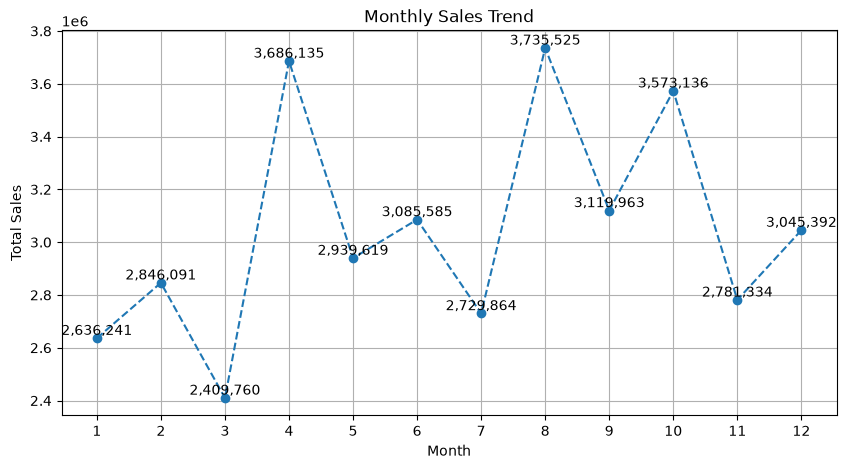

In [19]:
# Visualize monthly sales 
# use line plot visualize are monthly sales  

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(monthly_sales.index, monthly_sales.values, linestyle= '--', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(range(1, 13))
plt.grid(True)

for x, y in zip(monthly_sales.index, monthly_sales.values):
    plt.text(x, y, f'{y:,.0f}', ha='center', va='bottom')
    
plt.show()

In [20]:
# We'll analyze monthly sales growth (month-over-month percentage change) 
# to identify when sales increased or decreased.

# Task: Month-over-Month (MoM) sales growth
# Goal: Calculate the percentage increase or decrease in sales compared with the previous month.

monthly_growth = monthly_sales.pct_change() * 100

print(monthly_growth.round(2))

# Business insights
# 1. April recorded the highest monthly growth at 52.97%.
# 2. November recorded the biggest decline at 22.16%.
# 3. August showed strong growth of 36.84%.
# 4. Sales increased in February, April, June, August, October and December.


month
1       NaN
2      7.96
3    -15.33
4     52.97
5    -20.25
6      4.97
7    -11.53
8     36.84
9    -16.48
10    14.52
11   -22.16
12     9.49
Name: total_sales, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

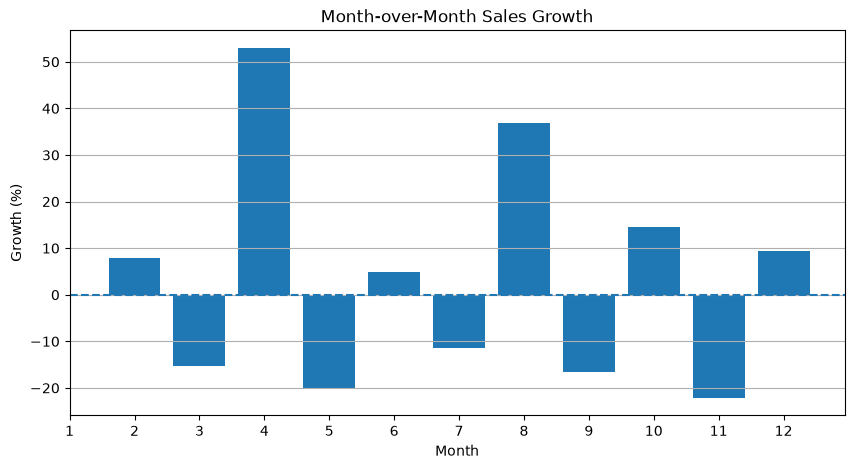

In [21]:
# Visualize monthly growth
# Let's create a bar chart to compare positive and negative growth. 

plt.figure(figsize=(10 , 5))

plt.bar(monthly_growth.index , monthly_growth.values)

plt.title('Month-over-Month Sales Growth')
plt.xlabel('Month')
plt.ylabel('Growth (%)')
plt.xticks(range(1, 13))
plt.axhline(y=0, linestyle='--')
plt.grid(axis='y')


plt.show

status
Delivered    774
Pending      115
Cancelled     78
Returned      33
Name: count, dtype: int64


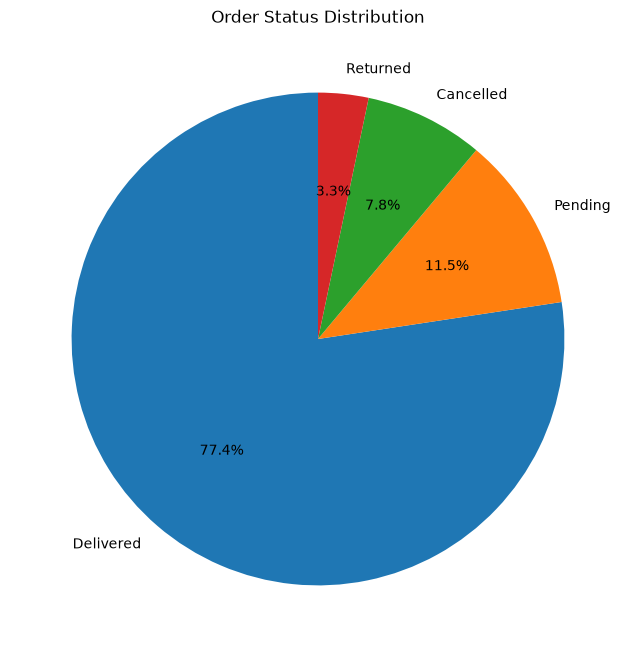

In [22]:
# Order status analysis
# Goal: Understand how many orders are Delivered, Pending, and Cancelled.

order_status = df['status'].value_counts()
print(order_status)

# Business insights:
# - Delivered orders: 77.4% of all orders.
# - Pending orders: 11.5%.
# - Cancelled orders: 7.8%.
# - Returned orders: 3.3% 

# Step 2: Visualize order status 
plt.figure(figsize=(8 , 8))

plt.pie(
    order_status.values,
    labels=order_status.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Order Status Distribution')

plt.show()

In [23]:
# Revenue by order status 
# How much revenue comes from Delivered, Pending, Cancelled, and Returned orders? 

status_revenue  = (
 df.groupby('status')['total_sales']
 .sum()
 .sort_values(ascending=False)
)

print(status_revenue)

status
Delivered    28928912.0
Pending       3070086.0
Cancelled     3061707.0
Returned      1527940.0
Name: total_sales, dtype: float64


In [ ]:
# Status-wise sales analysis
status_revenue = (
    df.groupby('status')['total_sales']
    .sum()
    .sort_values(ascending=False)
)

print(status_revenue)
# Business insights
# 1. Delivered orders account for the highest sales value.
# 2. Pending orders represent ₹30,70,086 in sales value.
# 3. Cancelled orders represent ₹30,61,707 in sales value.
# 4. Returned orders represent ₹15,27,940 in sales value.

status
Delivered    28928912.0
Pending       3070086.0
Cancelled     3061707.0
Returned      1527940.0
Name: total_sales, dtype: float64


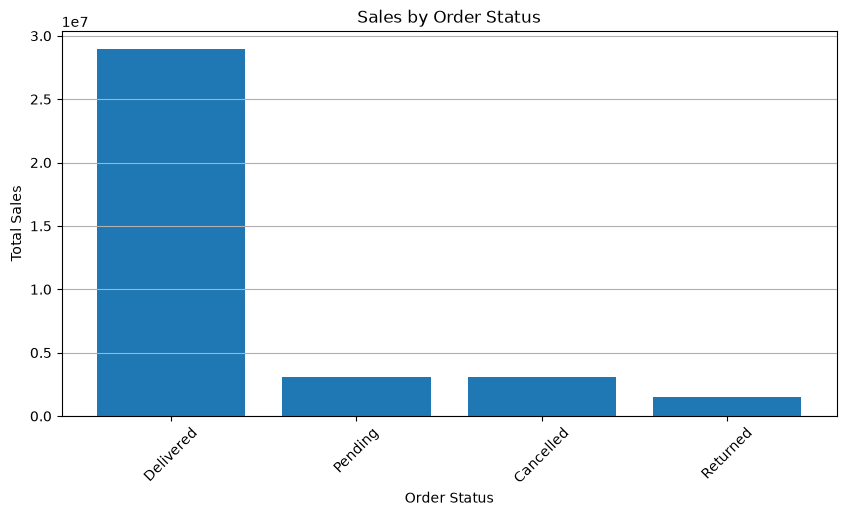

In [ ]:
# Next task — Visualize status-wise sales 
plt.figure(figsize=(10 , 5))

plt.bar(status_revenue.index , status_revenue.values)

plt.title('Sales by Order Status')
plt.xlabel('Order Status')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()

# Order status count analysis.
# Order status percentage distribution (pie chart).
# Status-wise sales calculation.
# Status-wise sales visualization (bar chart).


In [ ]:
# Regional order analysis
# Let's investigate how many orders come from each region.

region_orders = df['region'].value_counts()
print(region_orders)

# Business insights
# 1. East has the highest number of orders (211).
# 2. North has the lowest number of orders among the five known regions (191).
# 3. West generates the highest sales value, even though East has more orders.

region
East       211
West       202
South      198
Central    193
North      191
Unknown      5
Name: count, dtype: int64


In [ ]:
region_avg = (
df.groupby('region')['total_sales']
.mean()
.sort_values(ascending=False)

)
print(region_avg)

# Business insights
# 1. West has the highest AOV among known regions.
# 2. East has the lowest AOV among known regions.
# 3. West customers spend approximately ₹40,655 per order.
# 4. Unknown has a high average, but it contains only 5 orders, 
# so it is not a reliable regional comparison.


region
Unknown    56755.800000
West       40655.183168
South      38930.297980
Central    38219.694301
North      34943.073298
East       30017.971564
Name: total_sales, dtype: float64


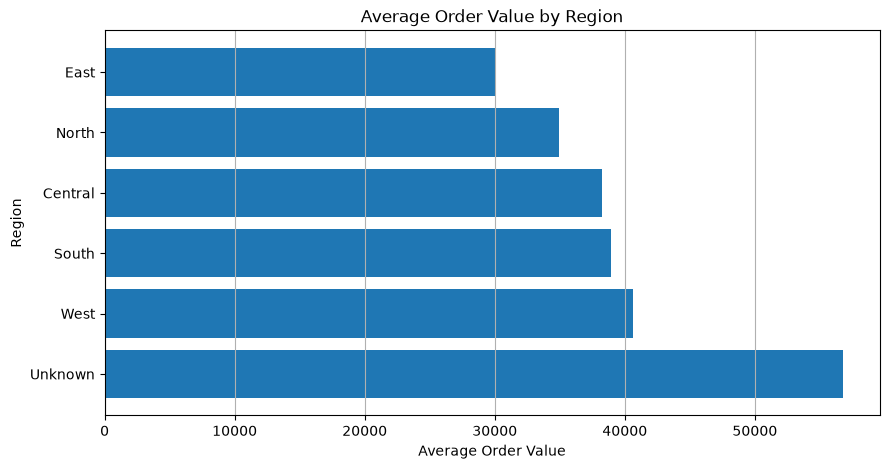

In [30]:
# Visualize regional AOV

plt.figure(figsize=(10 , 5))

plt.barh(region_avg.index , region_avg.values)
plt.title('Average Order Value by Region')
plt.xlabel('Average Order Value')
plt.ylabel('Region')
plt.grid(axis='x')

plt.show()


customer_id
CUST1006    803861.0
CUST1157    765972.0
CUST1158    689529.0
CUST1045    686815.0
CUST1233    668685.0
CUST1148    632116.0
CUST1104    609164.0
CUST1205    546910.0
CUST1059    541440.0
CUST1220    520042.0
Name: total_sales, dtype: float64


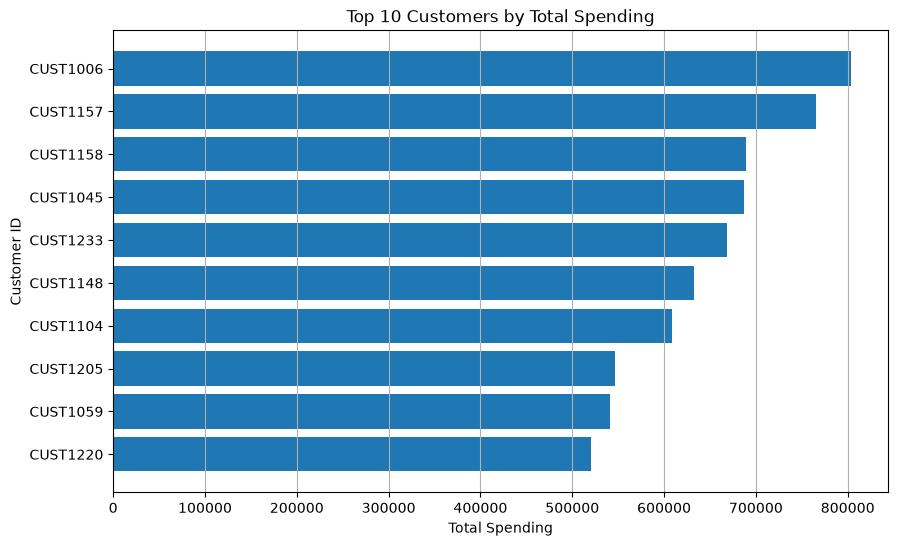

In [ ]:
# Final section: Customer Analysis
# Task 1: Top 10 customers by total spending
# Goal: Identify the 10 customers who generate the highest sales value.

customer_sales = (
    df.groupby('customer_id')['total_sales']
    .sum()
    .sort_values(ascending=False)
)

top_10_customers = customer_sales.head(10)

print(top_10_customers)

# Business insights:
# - CUST1006 is the highest-spending customer.
# - CUST1157 is the second-highest.
# - These customers could be considered 
# for customer loyalty or retention campaigns.

# Top 10 customers visualization
#  use by bar chart 
plt.figure(figsize=(10, 6))

plt.barh(top_10_customers.index, top_10_customers.values)

plt.title('Top 10 Customers by Total Spending')
plt.xlabel('Total Spending')
plt.ylabel('Customer ID')
plt.gca().invert_yaxis()
plt.grid(axis='x')

plt.show()

In [ ]:
# Customer Analysis — Task 2
# Next, let's find how many orders each customer placed.


customer_orders = (    df.groupby('customer_id')['order_id']   
                    .nunique()    
                    .sort_values(ascending=False))
print(customer_orders.head(10))

# Business insights:
# - CUST1051 and CUST1013 placed the most orders (11 each).
# - CUST1233 is interesting: it appears in both your top-spending and top-order customers.
# - Frequent customers may be good candidates for loyalty programs.



customer_id
CUST1051    11
CUST1013    11
CUST1233    10
CUST1081    10
CUST1039     9
CUST1104     9
CUST1190     9
CUST1069     8
CUST1243     8
CUST1099     8
Name: order_id, dtype: int64


In [ ]:
# Final customer analysis task: Customer segmentation
# Let's classify customers based on their total spending:
# - High Value: spending above ₹1,00,000
# - Medium Value: spending between ₹50,000 and ₹1,00,000
# - Low Value: spending below ₹50,000

customer_segment = pd.cut(
    customer_sales,
    bins=[0, 50000, 100000, float('inf')],
    labels=['Low Value', 'Medium Value', 'High Value']
)

print(customer_segment.value_counts())

# Business insights:
# - 121 customers belong to the High Value segment.
# - 50 customers belong to the Medium Value segment.
# - 77 customers belong to the Low Value segment.
# - High Value is the largest customer segment.

total_sales
High Value      121
Low Value        77
Medium Value     50
Name: count, dtype: int64


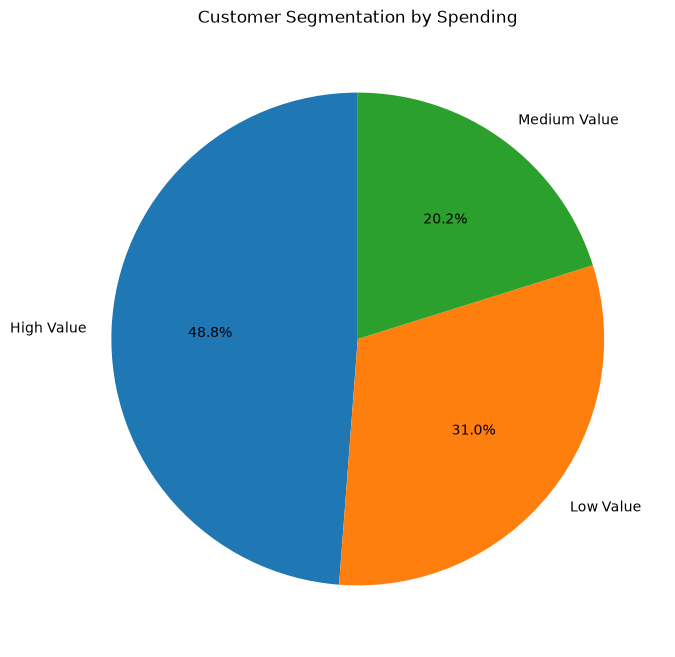

In [35]:
# Final task: Visualize customer segments

plt.figure(figsize=(8, 8))

plt.pie(
    customer_segment.value_counts().values,
    labels=customer_segment.value_counts().index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Segmentation by Spending')

plt.show()